# Etapa 3 — Comparação dos classificadores NSL-KDD

**Disciplina:** Inteligência Artificial · Ciência da Computação · PUC Minas

**Equipe — Grupo 3:** Davi Lucas Dias Morais; Gabriel Marques Fantini;
Julia Nathalia Sebastião Pinto; Thiago Tavares Willcox Noronha;
Túlio Geraldo da Costa Silva.

O objetivo é comparar classificadores de intrusão usando somente o **treino.csv oficial**,
com `class` como alvo (`normal` ou `anomaly`). A base contém 69.833 registros e 49 atributos;
as contagens e o esquema são conferidos novamente na execução. F1-macro é o critério
principal, com classes na ordem **normal, anomaly**. O teste sem rótulos não é usado.

Resultados históricos exploratórios (incluindo escolha antiga de épocas e RF ≈ 0,8744)
são referências de outro protocolo e não entram nas médias desta execução.
A quinta divisão histórica foi reutilizada: nenhum resultado aqui é chamado de teste intocado.

No Colab, execute todas as células em CPU. O orçamento é de até 210 ajustes sequenciais,
com a base completa e redes de 120 épocas. Reserve aproximadamente 15–60 minutos;
a duração depende da máquina. A cada ajuste, os resultados são persistidos.
Para sobreviver ao encerramento da sessão Colab, monte seu Drive e configure
`NSLKDD_DESTINO` para uma pasta persistente **antes de executar**. O destino padrão
fica no disco da sessão. Não publique essa pasta: ela contém índices e previsões por linha.

## Resultados observados no treino oficial

Este resumo agregado permite revisar os resultados sem novo treinamento. As células abaixo reproduzem a execução e geram suas próprias tabelas e gráficos.

Dados SHA-256: `9713c75938ef1e9e513975f256d65a80c4b05df533d35336c67387020bf76b7f`. Tipo: `official_training`; cinco folds externos e dois internos.

| Comparação | F1-macro médio | Desvio | Precisão anomaly | Recall anomaly |
| --- | ---: | ---: | ---: | ---: |
| Random Forest | 0.878042 | 0.006809 | 0.750286 | 0.792497 |
| SVM | 0.854939 | 0.006502 | 0.760448 | 0.694851 |
| MLP pequena (120 epocas) | 0.847189 | 0.007514 | 0.655863 | 0.784122 |
| MLP profunda (120 epocas) | 0.844761 | 0.008903 | 0.655827 | 0.773657 |
| preparo:referencia | 0.863520 | 0.005558 | 0.765582 | 0.720954 |
| preparo:rf_over | 0.878817 | 0.005054 | 0.751176 | 0.794564 |
| preparo:rf_under | 0.868041 | 0.006386 | 0.704497 | 0.807964 |
| preparo:rf_ordinal | 0.867408 | 0.006506 | 0.763918 | 0.736822 |
| preparo:rf_sem_escala | 0.863396 | 0.005757 | 0.765649 | 0.720457 |
| preparo:rf_todas_linhas | 0.866722 | 0.006359 | 0.765333 | 0.732926 |
| preparo:rf_redundancias_A | 0.867617 | 0.007797 | 0.763935 | 0.737603 |
| preparo:rf_pca60 | 0.859583 | 0.005015 | 0.761469 | 0.710440 |
| selecao_global_aninhada | 0.878817 | 0.005054 | 0.751176 | 0.794564 |

**Pipeline recomendado:** `rf_over`. A escolha usa F1-macro médio. A RF com oversampling obteve 0,878817 e a RF ponderada, 0,878042: a diferença de 0,000775 é pequena e não estabelece superioridade estatística. Desvios, erros por classe, gap treino–validação e custo constam das tabelas e figuras abaixo. Escolha informada pela comparacao externa; desempenho do vencedor nao e estimativa final independente. Folds internos sobrepostos nao sao repeticoes independentes. Quinta historica reutilizada.

In [1]:
import json, os, subprocess, sys
from pathlib import Path
from IPython.display import display, Markdown, Image

if sys.version_info < (3, 12):
    raise RuntimeError("Use um runtime Python 3.12 ou posterior compatível com os pins.")
BASE = Path("temp/stage3_notebook").resolve()
CODIGO = BASE / "codigo"
CODIGO.mkdir(parents=True, exist_ok=True)
DESTINO = Path(os.environ.get("NSLKDD_DESTINO", "temp/stage3_runs/comparacao_cpu")).resolve()
SAIDA = DESTINO / "resumo"
AMBIENTE = os.environ.copy()
AMBIENTE.update(OMP_NUM_THREADS="1", OPENBLAS_NUM_THREADS="1", MKL_NUM_THREADS="1")

In [2]:
PINS = ['numpy==2.5.4', 'pandas==3.0.1', 'scipy==1.18.1', 'scikit-learn==1.7.2', 'imbalanced-learn==0.14.1', 'joblib==1.6.0', 'threadpoolctl==3.8.0', 'sklearn-compat==0.1.6', 'matplotlib==3.10.8']
esperadas = dict(p.split("==") for p in PINS)
bibliotecas = BASE / "bibliotecas"
AMBIENTE["PYTHONPATH"] = os.pathsep.join([str(CODIGO), str(bibliotecas)])
consulta = "import json; from importlib.metadata import version; print(json.dumps({p: version(p) for p in " + repr(list(esperadas)) + "}))"
def consultar():
    r = subprocess.run([sys.executable, "-c", consulta], env=AMBIENTE, capture_output=True, text=True)
    return json.loads(r.stdout) if r.returncode == 0 else {}
if consultar() != esperadas:
    subprocess.run([sys.executable, "-m", "pip", "install", "--upgrade", "--target", str(bibliotecas), *PINS], check=True)
if consultar() != esperadas:
    raise RuntimeError("As versões instaladas divergem das versões de referência.")
print(consultar())

{'numpy': '2.5.4', 'pandas': '3.0.1', 'scipy': '1.18.1', 'scikit-learn': '1.7.2', 'imbalanced-learn': '0.14.1', 'joblib': '1.6.0', 'threadpoolctl': '3.8.0', 'sklearn-compat': '0.1.6', 'matplotlib': '3.10.8'}


## Preparação e protocolo

As células seguintes escrevem os módulos mantidos no projeto. A divisão agrupada usa entradas
iguais na representação C como grupo, inclusive quando há rótulos conflitantes.
São cinco folds externos e dois internos em cada treino externo, sempre com semente 42.
Imputação, vocabulário, escala, PCA, deduplicação e amostragem são ajustados somente no treino
correspondente. A validação mantém todas as linhas. As comparações compartilham os folds externos.

RF compara profundidade 12/livre e pesos ausentes/`balanced_subsample`, com 100 árvores.
SVM compara linear C=0,1 e RBF C=10; somente ajustes convergidos são elegíveis.
MLPs usam (16,) e (64,32,16), Adam, oversampling 0,5 e 120 épocas fixas.
PyTorch e CUDA são opcionais e não fazem parte deste orçamento.

Na RF livre sem ponderação, variamos um fator por vez: over/undersampling, ordinal/one-hot,
escala/ausência de escala, deduplicação/todas as linhas, redundâncias A/C e PCA até 60 componentes.
Regras de inconsistência e exclusões aprovadas permanecem em todos os candidatos;
o CSV original nunca é alterado.

In [3]:
(CODIGO / 'dados_etapa2.py').write_bytes(b'"""Prepara os dados e cria divisoes agrupadas para as etapas 2 e 3."""\r\n\r\nimport numpy as np\r\nimport pandas as pd\r\nfrom pathlib import Path\r\nfrom sklearn.model_selection import StratifiedGroupKFold\r\n\r\nALVO = "class"\r\nCOLUNAS_EXCLUIDAS_EXPERIMENTOS = (\r\n    "num_outbound_cmds", "tempo_resposta_analista_min", "tipo_alerta_soc", "score_ids_legado",\r\n)\r\nSEMENTE = 42\r\nNOMINAIS = ["protocol_type", "service", "flag", "protocolo_cod"]\r\nCOPIAS = ["src_bytes_kb", "dst_bytes_kb", "same_srv_pct", "protocolo_cod"]\r\n\r\n\r\ndef carregar_treino(caminho: str | Path) -> pd.DataFrame:\r\n    """L\xc3\xaa o CSV oficial e valida a coluna alvo."""\r\n    caminho = Path(caminho)\r\n    if not caminho.is_file():\r\n        raise FileNotFoundError(f"Base oficial n\xc3\xa3o encontrada: {caminho}")\r\n    dados = pd.read_csv(caminho)\r\n    if ALVO not in dados or dados.empty:\r\n        raise ValueError(f"A base deve ser n\xc3\xa3o vazia e conter {ALVO!r}.")\r\n    if dados[ALVO].isna().any() or not set(dados[ALVO].unique()).issubset({"normal", "anomaly"}):\r\n        raise ValueError("A coluna class deve conter somente normal ou anomaly, sem aus\xc3\xaancias.")\r\n    return dados.copy()\r\n\r\n\r\ndef identificar_taxas(dados: pd.DataFrame) -> list[str]:\r\n    """Retorna apenas fra\xc3\xa7\xc3\xb5es ``*_rate``; ``*_pct`` usa escala percentual."""\r\n    return [c for c in dados.select_dtypes(include="number") if c.lower().endswith("rate")]\r\n\r\n\r\ndef preparar_base(dados):\r\n    entradas = dados.drop(columns=["class", *COLUNAS_EXCLUIDAS_EXPERIMENTOS])\r\n    for coluna in NOMINAIS:\r\n        entradas[coluna] = entradas[coluna].astype("string").str.strip().str.casefold().replace("", pd.NA)\r\n\r\n    invalidos = {}\r\n    for coluna in ("duration", "src_bytes", "dst_bytes"):\r\n        invalidos[coluna] = entradas[coluna].lt(0)\r\n    for coluna in identificar_taxas(entradas):\r\n        invalidos[coluna] = entradas[coluna].notna() & ~entradas[coluna].between(0, 1)\r\n    invalidos["src_bytes_kb"] = invalidos["src_bytes"] | entradas["src_bytes_kb"].lt(0)\r\n    invalidos["dst_bytes_kb"] = invalidos["dst_bytes"] | entradas["dst_bytes_kb"].lt(0)\r\n    invalidos["total_bytes"] = invalidos["src_bytes"] | invalidos["dst_bytes"] | entradas["total_bytes"].lt(0)\r\n    percentual = entradas["same_srv_pct"]\r\n    invalidos["same_srv_pct"] = invalidos["same_srv_rate"] | (percentual.notna() & ~percentual.between(0, 100))\r\n    for coluna, mascara in invalidos.items():\r\n        entradas[coluna] = entradas[coluna].mask(mascara)\r\n\r\n    representacoes = {\r\n        "A": entradas,\r\n        "B": entradas.drop(columns=COPIAS),\r\n        "C": entradas.drop(columns=[*COPIAS, "total_bytes"]),\r\n    }\r\n    assert [m.shape[1] for m in representacoes.values()] == [45, 41, 40]\r\n    grupos = representacoes["C"].groupby(list(representacoes["C"]), dropna=False, sort=False).ngroup()\r\n    assert grupos.notna().all()\r\n    return representacoes, grupos\r\n\r\n\r\ndef escolher_linhas(x, y, indices, regra):\r\n    if regra == "todas":\r\n        return indices\r\n    chaves = x.iloc[indices].assign(rotulo=y[indices])\r\n    mascara = np.ones(len(indices), dtype=bool)\r\n    if regra in {"sem_conflitos", "sem_ambos"}:\r\n        grupos = chaves.groupby(list(x), dropna=False, sort=False)["rotulo"]\r\n        mascara &= grupos.transform("nunique").to_numpy() == 1\r\n    if regra in {"sem_duplicatas", "sem_ambos"}:\r\n        mascara &= ~chaves.duplicated().to_numpy()\r\n    return indices[mascara]\r\n\r\n\r\ndef separar_divisoes(representacoes, y, grupos):\r\n    divisor = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEMENTE)\r\n    particoes = list(divisor.split(representacoes["C"], y, grupos))\r\n    reserva = particoes[-1][1]\r\n    divisoes = []\r\n    for fold, (treino, validacao) in enumerate(particoes, 1):\r\n        if fold != 5:\r\n            treino = np.setdiff1d(treino, reserva)\r\n            assert set(grupos.iloc[treino]).isdisjoint(grupos.iloc[reserva])\r\n            assert set(grupos.iloc[validacao]).isdisjoint(grupos.iloc[reserva])\r\n        assert set(grupos.iloc[treino]).isdisjoint(grupos.iloc[validacao])\r\n        divisoes.append((fold, treino, validacao))\r\n    return divisoes\r\n')

4080

In [4]:
(CODIGO / 'tecnicas_etapa2.py').write_bytes(b'"""Transformacoes ajustadas apenas no treino de cada divisao."""\r\n\r\nimport numpy as np\r\nimport pandas as pd\r\nfrom sklearn import config_context\r\nfrom sklearn.impute import KNNImputer, SimpleImputer\r\nfrom sklearn.preprocessing import MinMaxScaler, OneHotEncoder, OrdinalEncoder, RobustScaler, StandardScaler\r\nfrom dados_etapa2 import NOMINAIS, SEMENTE, escolher_linhas\r\n\r\n\r\ndef transformar_numericas(treino, validacao, metodo, escala):\r\n    treino = treino.to_numpy(dtype=np.float64, na_value=np.nan).copy()\r\n    validacao = validacao.to_numpy(dtype=np.float64, na_value=np.nan).copy()\r\n    treino[~np.isfinite(treino)] = np.nan\r\n    validacao[~np.isfinite(validacao)] = np.nan\r\n    # Uma entrada sem observacoes no ajuste recebe zero em ambas as parcelas.\r\n    # Valores observados apenas na validacao nao participam do ajuste do KNN.\r\n    if metodo == "knn":\r\n        vazias = np.isnan(treino).all(axis=0)\r\n        treino[:, vazias] = 0.0\r\n        validacao[:, vazias] = 0.0\r\n    if metodo == "mediana_indicador":\r\n        tem_ausencia = np.isnan(treino).any(axis=0)\r\n        indicadores_treino = np.isnan(treino[:, tem_ausencia])\r\n        indicadores_val = np.isnan(validacao[:, tem_ausencia])\r\n    if metodo == "knn":\r\n        # Limita o custo de vizinhan\xc3\xa7a a uma amostra sem r\xc3\xb3tulos da parte de treino.\r\n        normalizador = StandardScaler().fit(treino)\r\n        amostra = np.random.default_rng(SEMENTE).choice(len(treino), size=min(2000, len(treino)), replace=False)\r\n        imputador = KNNImputer(n_neighbors=5, keep_empty_features=True)\r\n        imputador.fit(normalizador.transform(treino[amostra]))\r\n        with config_context(working_memory=48):\r\n            treino = normalizador.inverse_transform(imputador.transform(normalizador.transform(treino)))\r\n            validacao = normalizador.inverse_transform(imputador.transform(normalizador.transform(validacao)))\r\n    else:\r\n        estrategia = "mean" if metodo == "media" else "median"\r\n        imputador = SimpleImputer(strategy=estrategia, keep_empty_features=True)\r\n        treino, validacao = imputador.fit_transform(treino), imputador.transform(validacao)\r\n    normalizadores = {"zscore": StandardScaler, "robusta": RobustScaler, "minmax": MinMaxScaler}\r\n    if escala in normalizadores:\r\n        normalizador = normalizadores[escala]()\r\n        treino, validacao = normalizador.fit_transform(treino), normalizador.transform(validacao)\r\n    if metodo == "mediana_indicador":\r\n        treino = np.column_stack((treino, indicadores_treino))\r\n        validacao = np.column_stack((validacao, indicadores_val))\r\n    return treino, validacao\r\n\r\n\r\ndef transformar_categoricas(treino, validacao, metodo, codificacao):\r\n    estrategia = "most_frequent" if metodo == "moda" else "constant"\r\n    colunas = list(treino)\r\n    colunas_treino, colunas_validacao = [], []\r\n    for coluna in colunas:\r\n        valores_treino = treino[[coluna]].to_numpy(dtype=object, na_value=np.nan)\r\n        valores_validacao = validacao[[coluna]].to_numpy(dtype=object, na_value=np.nan)\r\n        # A moda nao existe quando toda a coluna do ajuste esta ausente.\r\n        # Nesse caso a categoria explicita mantem a posicao da coluna.\r\n        estrategia_coluna = "constant" if pd.isna(valores_treino).all() else estrategia\r\n        imputador = SimpleImputer(strategy=estrategia_coluna, fill_value="__ausente__",\r\n                                 keep_empty_features=True)\r\n        colunas_treino.append(imputador.fit_transform(valores_treino))\r\n        colunas_validacao.append(imputador.transform(valores_validacao))\r\n    treino = np.column_stack(colunas_treino)\r\n    validacao = np.column_stack(colunas_validacao)\r\n    if codificacao == "inteiros":\r\n        codificador = OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1)\r\n        return codificador.fit_transform(treino), codificador.transform(validacao)\r\n    cod_treino, cod_val = [], []\r\n    for i, coluna in enumerate(colunas):\r\n        agrupar = codificacao == "onehot_raros" and coluna == "service"\r\n        codificador = OneHotEncoder(\r\n            sparse_output=False,\r\n            min_frequency=20 if agrupar else None,\r\n            handle_unknown="infrequent_if_exist" if agrupar else "ignore",\r\n        )\r\n        cod_treino.append(codificador.fit_transform(treino[:, i:i + 1]))\r\n        cod_val.append(codificador.transform(validacao[:, i:i + 1]))\r\n    return np.column_stack(cod_treino), np.column_stack(cod_val)\r\n\r\n\r\ndef transformar(x, y, indices, validacao, config):\r\n    indices = escolher_linhas(x, y, indices, config.linhas)\r\n    treino, validacao = x.iloc[indices], x.iloc[validacao]\r\n    categoricas = [c for c in NOMINAIS if c in x]\r\n    numericas = x.columns.drop(categoricas).tolist()\r\n    num_treino, num_val = transformar_numericas(treino[numericas], validacao[numericas], config.numericos, config.escala)\r\n    cat_treino, cat_val = transformar_categoricas(treino[categoricas], validacao[categoricas], config.nominais, config.codificacao)\r\n    return np.column_stack((num_treino, cat_treino)), np.column_stack((num_val, cat_val)), y[indices]\r\n')

5081

In [5]:
(CODIGO / 'stage3_evaluation.py').write_bytes(b'"""Infraestrutura da Etapa 3: selecao interna e avaliacao externa por grupos.\n\nNenhum treinamento roda ao importar este modulo. Resultados oficiais exigem\nexplicitamente o caminho do treino.csv; fixtures recebem tipo sint\xc3\xa9tico.\n"""\n\nfrom dataclasses import asdict, dataclass, field\nfrom hashlib import sha256\nfrom importlib.metadata import PackageNotFoundError, version\nimport json\nimport os\nfrom pathlib import Path\nimport platform\nimport subprocess\nimport sys\nfrom time import perf_counter\n\nfrom imblearn.over_sampling import RandomOverSampler\nfrom imblearn.under_sampling import RandomUnderSampler\nimport numpy as np\nimport pandas as pd\nfrom sklearn.ensemble import RandomForestClassifier\nfrom sklearn.decomposition import PCA\nfrom sklearn.metrics import accuracy_score, classification_report, confusion_matrix, f1_score\nfrom sklearn.model_selection import StratifiedGroupKFold\nfrom sklearn.neural_network import MLPClassifier\nfrom sklearn.svm import LinearSVC, SVC\n\nfrom dados_etapa2 import SEMENTE, carregar_treino, preparar_base\nfrom tecnicas_etapa2 import transformar\n\n\nCLASSES = ("normal", "anomaly")\nPACOTES = ("numpy", "pandas", "scipy", "scikit-learn", "imbalanced-learn",\n           "joblib", "threadpoolctl", "sklearn-compat", "torch", "cuml")\n\n\n@dataclass(frozen=True)\nclass Configuracao:\n    nome: str\n    modelo: str\n    parametros: dict = field(default_factory=dict)\n    linhas: str = "sem_duplicatas"\n    numericos: str = "mediana"\n    nominais: str = "ausencia"\n    codificacao: str = "onehot"\n    escala: str = "zscore"\n    balanceamento: str = "nenhum"\n    representacao: str = "C"\n    reducao: str = "nenhuma"\n\n\nCONFIGURACOES_REFERENCIA = (\n    Configuracao("rf_livre_ponderada", "random_forest",\n                 {"n_estimators": 100, "max_depth": None, "class_weight": "balanced_subsample",\n                  "min_samples_leaf": 2, "max_features": "sqrt", "criterion": "gini"}),\n    Configuracao("svm_rbf_c10", "svm_rbf", {"C": 10.0, "gamma": "scale"}),\n    Configuracao("svm_linear_c01", "svm_linear", {"C": 0.1}),\n    Configuracao("mlp_pequena_120", "mlp_pequena", {"epocas": 120}, balanceamento="over_0_5"),\n    Configuracao("mlp_profunda_120", "mlp_profunda", {"epocas": 120}, balanceamento="over_0_5"),\n    Configuracao("pytorch_profunda_120", "pytorch_profunda", {"epocas": 120, "dispositivo": "cpu"},\n                 balanceamento="over_0_5"),\n)\n\n\ndef _digest_indices(indices):\n    return sha256(np.asarray(indices, dtype="<i8").tobytes()).hexdigest()\n\n\ndef planejar_divisoes(dados, *, externas=5, internas=3, semente=SEMENTE):\n    """Constroi folds externos; cada treino externo recebe folds internos proprios."""\n    representacoes, grupos = preparar_base(dados)\n    x = representacoes["C"]\n    y = dados["class"].to_numpy()\n    if externas < 2 or internas < 2:\n        raise ValueError("Sao necessarias pelo menos duas divisoes em cada nivel.")\n    outer = StratifiedGroupKFold(n_splits=externas, shuffle=True, random_state=semente)\n    plano = []\n    for numero, (treino, validacao) in enumerate(outer.split(x, y, grupos), 1):\n        inner = StratifiedGroupKFold(n_splits=internas, shuffle=True, random_state=semente)\n        interno = []\n        for subtreino, subvalidacao in inner.split(x.iloc[treino], y[treino], grupos.iloc[treino]):\n            ajuste, val_interna = treino[subtreino], treino[subvalidacao]\n            if set(grupos.iloc[ajuste]) & set(grupos.iloc[val_interna]):\n                raise AssertionError("Grupos sobrepostos na selecao interna")\n            interno.append((ajuste, val_interna))\n        if set(grupos.iloc[treino]) & set(grupos.iloc[validacao]):\n            raise AssertionError("Grupos sobrepostos na avaliacao externa")\n        plano.append((numero, treino, validacao, interno))\n    return x, y, grupos, plano\n\n\nclass _MLPExistente:\n    """Mantem o treino por partial_fit e as arquiteturas dos notebooks atuais."""\n\n    def __init__(self, camadas, epocas):\n        self.epocas = epocas\n        self.modelo = MLPClassifier(\n            hidden_layer_sizes=camadas, activation="relu", solver="adam", batch_size=512,\n            alpha=0.0001, learning_rate_init=0.001, shuffle=True,\n            random_state=np.random.RandomState(SEMENTE), early_stopping=False,\n            max_iter=epocas + 1, n_iter_no_change=epocas + 1,\n        )\n\n    def fit(self, x, y):\n        rotulos = (np.asarray(y) == "anomaly").astype(np.int32)\n        for _ in range(self.epocas):\n            self.modelo.partial_fit(x.astype(np.float32), rotulos, classes=[0, 1])\n        self.epocas_concluidas_ = len(self.modelo.loss_curve_)\n        if not np.isfinite(self.modelo.loss_curve_).all():\n            raise ValueError("Perdas MLP nao finitas")\n        return self\n\n    def predict(self, x):\n        previsto = self.modelo.predict(x.astype(np.float32))\n        return np.where(previsto == 1, "anomaly", "normal")\n\n\nclass _PyTorchExistente:\n    """Adapter opcional da rede profunda, com as camadas do notebook PyTorch."""\n\n    def __init__(self, epocas, dispositivo):\n        self.epocas = epocas\n        self.dispositivo = dispositivo\n\n    def fit(self, x, y):\n        os.environ.setdefault("CUBLAS_WORKSPACE_CONFIG", ":4096:8")\n        import torch\n        from torch import nn\n\n        if self.dispositivo == "cuda" and not torch.cuda.is_available():\n            raise RuntimeError("CUDA indisponivel no PyTorch deste ambiente")\n        device = torch.device(self.dispositivo)\n        torch.manual_seed(SEMENTE)\n        torch.use_deterministic_algorithms(True)\n        gerador = torch.Generator(device=device).manual_seed(SEMENTE)\n        camadas = []\n        entradas = x.shape[1]\n        for indice, saidas in enumerate((128, 64, 32, 16)):\n            camadas.extend((nn.Linear(entradas, saidas), nn.ReLU()))\n            if indice < 3:\n                camadas.append(nn.Dropout(0.15))\n            entradas = saidas\n        camadas.append(nn.Linear(entradas, 1))\n        self.modelo = nn.Sequential(*camadas).to(device)\n        entradas_t = torch.as_tensor(np.asarray(x, dtype=np.float32, order="C"), device=device)\n        rotulos_t = torch.as_tensor((np.asarray(y) == "anomaly").astype(np.float32), device=device)\n        perda = nn.BCEWithLogitsLoss()\n        otimizador = torch.optim.Adam(self.modelo.parameters(), lr=0.001, weight_decay=0.0001)\n        self.modelo.train()\n        for _ in range(self.epocas):\n            indices = torch.randperm(len(rotulos_t), generator=gerador, device=device)\n            for lote in indices.split(512):\n                otimizador.zero_grad(set_to_none=True)\n                valor = perda(self.modelo(entradas_t[lote]).squeeze(1), rotulos_t[lote])\n                if not torch.isfinite(valor):\n                    raise RuntimeError("Perda nao finita no treinamento PyTorch")\n                valor.backward()\n                otimizador.step()\n        self.epocas_concluidas_ = self.epocas\n        return self\n\n    def predict(self, x):\n        import torch\n\n        self.modelo.eval()\n        device = next(self.modelo.parameters()).device\n        entradas = torch.as_tensor(np.asarray(x, dtype=np.float32, order="C"), device=device)\n        with torch.inference_mode():\n            previsto = (self.modelo(entradas).squeeze(1) >= 0).cpu().numpy()\n        return np.where(previsto, "anomaly", "normal")\n\n\ndef criar_modelo(config):\n    parametros = dict(config.parametros)\n    if config.modelo == "random_forest":\n        return RandomForestClassifier(random_state=SEMENTE, n_jobs=1, **parametros)\n    if config.modelo == "svm_linear":\n        return LinearSVC(dual=False, max_iter=5000, random_state=SEMENTE, **parametros)\n    if config.modelo == "svm_rbf":\n        return SVC(kernel="rbf", cache_size=256, max_iter=200_000, **parametros)\n    if config.modelo in ("mlp_pequena", "mlp_profunda"):\n        camadas = (16,) if config.modelo == "mlp_pequena" else (64, 32, 16)\n        return _MLPExistente(camadas, parametros.get("epocas", 120))\n    if config.modelo == "pytorch_profunda":\n        return _PyTorchExistente(parametros.get("epocas", 120), parametros.get("dispositivo", "cpu"))\n    raise ValueError(f"Modelo desconhecido: {config.modelo}")\n\n\ndef status_convergencia(modelo, familia):\n    """Retorna (estado, elegivel); ausencia de status nunca prova convergencia."""\n    if familia == "svm_linear":\n        iteracoes = getattr(modelo, "n_iter_", None)\n        limite = getattr(modelo, "max_iter", None)\n        if iteracoes is None or limite is None:\n            return "desconhecido", False\n        elegivel = bool(np.all(np.asarray(iteracoes) < limite))\n        return ("convergiu" if elegivel else "limite_de_iteracoes"), elegivel\n    if familia == "svm_rbf":\n        estado = getattr(modelo, "fit_status_", None)\n        if estado is None:\n            return "desconhecido", False\n        return ("convergiu" if estado == 0 else f"fit_status_{estado}"), bool(estado == 0)\n    if familia.startswith("mlp_") or familia == "pytorch_profunda":\n        concluidas = getattr(modelo, "epocas_concluidas_", None)\n        elegivel = concluidas == getattr(modelo, "epocas", None) and concluidas is not None\n        return ("epocas_completas" if elegivel else "epocas_incompletas"), bool(elegivel)\n    return "ajuste_completo", True\n\n\ndef calcular_metricas(y_real, y_previsto):\n    real, previsto = np.asarray(y_real), np.asarray(y_previsto)\n    if real.shape != previsto.shape or real.ndim != 1:\n        raise ValueError("Rotulos reais e previstos devem ter o mesmo formato")\n    if not set(real).issubset(CLASSES) or not set(previsto).issubset(CLASSES):\n        raise ValueError("Rotulos fora de normal/anomaly")\n    relatorio = classification_report(real, previsto, labels=CLASSES,\n                                       output_dict=True, zero_division=0)\n    return {\n        "f1_macro": float(f1_score(real, previsto, labels=CLASSES, average="macro", zero_division=0)),\n        "acuracia": float(accuracy_score(real, previsto)),\n        "precisao_macro": float(relatorio["macro avg"]["precision"]),\n        "recall_macro": float(relatorio["macro avg"]["recall"]),\n        "matriz": confusion_matrix(real, previsto, labels=CLASSES).tolist(),\n        "por_classe": {classe: {chave: float(relatorio[classe][chave])\n                                 for chave in ("precision", "recall", "f1-score", "support")}\n                       for classe in CLASSES},\n    }\n\n\ndef avaliar_divisao(x, y, ajuste, validacao, config, *, fabrica=criar_modelo):\n    """Mede um pipeline sem ajustar transformacoes nem amostragem na validacao."""\n    ajuste = np.asarray(ajuste, dtype=int)\n    validacao = np.asarray(validacao, dtype=int)\n    if set(ajuste) & set(validacao):\n        raise ValueError("Ajuste e validacao se sobrepoem")\n    inicio = perf_counter()\n    x_tr, x_val, y_tr = transformar(x, y, ajuste, validacao, config)\n    if config.reducao == "pca60":\n        redutor = PCA(n_components=min(60, x_tr.shape[1], len(x_tr)),\n                      svd_solver="full", random_state=SEMENTE)\n        x_tr, x_val = redutor.fit_transform(x_tr), redutor.transform(x_val)\n    elif config.reducao != "nenhuma":\n        raise ValueError(f"Reducao desconhecida: {config.reducao}")\n    segundos_preparo = perf_counter() - inicio\n    if not np.isfinite(x_tr).all() or not np.isfinite(x_val).all():\n        raise ValueError("Transformacao produziu valores nao finitos")\n    x_treino_original, y_treino_original = x_tr, y_tr\n    if config.balanceamento == "over_0_5":\n        x_tr, y_tr = RandomOverSampler(sampling_strategy=0.5, random_state=SEMENTE).fit_resample(x_tr, y_tr)\n    elif config.balanceamento == "under_0_5":\n        x_tr, y_tr = RandomUnderSampler(sampling_strategy=0.5, random_state=SEMENTE).fit_resample(x_tr, y_tr)\n    elif config.balanceamento != "nenhum":\n        raise ValueError(f"Balanceamento desconhecido: {config.balanceamento}")\n    modelo = fabrica(config)\n    inicio = perf_counter()\n    modelo.fit(x_tr, y_tr)\n    segundos_ajuste = perf_counter() - inicio\n    estado, elegivel = status_convergencia(modelo, config.modelo)\n    inicio = perf_counter()\n    previsto = modelo.predict(x_val)\n    segundos_previsao = perf_counter() - inicio\n    metricas = calcular_metricas(y[validacao], previsto)\n    treino_previsto = modelo.predict(x_treino_original)\n    return {\n        "configuracao": asdict(config), "status_convergencia": estado,\n        "elegivel": elegivel, "metricas": metricas,\n        "f1_macro_ajuste": calcular_metricas(y_treino_original, treino_previsto)["f1_macro"],\n        "linhas_ajuste": int(len(y_tr)), "linhas_validacao": int(len(validacao)),\n        "colunas": int(x_tr.shape[1]), "indices_validacao": validacao.tolist(),\n        "previsoes": np.asarray(previsto).tolist(),\n        "rotulos_reais": np.asarray(y[validacao]).tolist(),\n        "linhas_antes_amostragem": int(len(y_treino_original)),\n        "classes_ajuste": {c: int(np.sum(y_tr == c)) for c in CLASSES},\n        "perdas_treino": [float(v) for v in getattr(getattr(modelo, "modelo", None), "loss_curve_", [])],\n        "tempos_s": {"preparo": segundos_preparo, "ajuste": segundos_ajuste,\n                     "previsao": segundos_previsao},\n    }\n\n\ndef _versoes():\n    resultado = {}\n    for pacote in PACOTES:\n        try:\n            resultado[pacote] = version(pacote)\n        except PackageNotFoundError:\n            resultado[pacote] = None\n    return resultado\n\n\ndef _commit():\n    resposta = subprocess.run(["git", "rev-parse", "HEAD"], cwd=Path(__file__).parent,\n                              capture_output=True, text=True)\n    return resposta.stdout.strip() if resposta.returncode == 0 else None\n\n\ndef hashes_fontes():\n    return {nome: sha256(Path(__file__).with_name(nome).read_bytes()).hexdigest()\n            for nome in ("stage3_evaluation.py", "dados_etapa2.py", "tecnicas_etapa2.py")}\n\n\ndef _chave_resultado(r):\n    return (r["etapa"], r["fold_externo"], r.get("fold_interno"),\n            r.get("configuracao", {}).get("nome", r.get("comparacao")))\n\n\ndef _ler_registros(caminho):\n    """Tolera somente a ultima linha incompleta apos interrupcao da escrita."""\n    dados = caminho.read_bytes()\n    fim = dados.rfind(b"\\n") + 1\n    if fim < len(dados):\n        # Preserva o fragmento para diagnostico antes de retirar o registro parcial.\n        caminho.with_suffix(".partial").write_bytes(dados[fim:])\n        with caminho.open("r+b") as arquivo:\n            arquivo.truncate(fim)\n    linhas = [json.loads(l) for l in dados[:fim].splitlines()]\n    chaves = [_chave_resultado(r) for r in linhas]\n    if len(chaves) != len(set(chaves)):\n        raise ValueError("Resultados duplicados no checkpoint")\n    for r in linhas:\n        if "metricas" in r and calcular_metricas(r["rotulos_reais"], r["previsoes"]) != r["metricas"]:\n            raise ValueError("Metricas persistidas inconsistentes com as previsoes")\n    return linhas\n\n\ndef preparar_entrada(entrada, tipo_dados):\n    if tipo_dados == "official_training":\n        if not isinstance(entrada, (str, os.PathLike)):\n            raise ValueError("A origem oficial deve ser o caminho de treino.csv")\n        caminho = Path(entrada)\n        if caminho.name != "treino.csv":\n            raise ValueError("A origem oficial deve ser treino.csv")\n        dados = carregar_treino(caminho)\n        digest = sha256(caminho.read_bytes()).hexdigest()\n        origem = str(caminho.resolve())\n    elif tipo_dados == "synthetic_test" and isinstance(entrada, pd.DataFrame):\n        dados = entrada.copy(deep=True)\n        digest = sha256(pd.util.hash_pandas_object(dados, index=True).values.tobytes()).hexdigest()\n        origem = "fixture_sintetica"\n    else:\n        raise ValueError("Informe treino.csv oficial ou DataFrame sintetico e tipo correspondente")\n    if dados.empty or "class" not in dados or dados["class"].isna().any() or not set(dados["class"]).issubset(CLASSES):\n        raise ValueError("Alvo class invalido")\n    return dados, digest, origem\n\n\ndef resultados_compativeis(primeiro, segundo):\n    """Somente avaliacoes do mesmo CSV e dos mesmos indices podem ser pareadas."""\n    chaves = ("tipo_dados", "sha256_dados", "protocolo_sha256", "fold_externo",\n              "indices_validacao_sha256")\n    return all(chave in primeiro and chave in segundo and primeiro[chave] is not None\n               and primeiro[chave] == segundo[chave] for chave in chaves)\n\n\ndef executar_avaliacao(entrada, configuracoes, destino, *, tipo_dados,\n                      externas=5, internas=3, semente=SEMENTE, fabrica=criar_modelo,\n                      comparacoes=None, retomar=False):\n    """Seleciona por folds internos e avalia cada escolha no fold externo.\n\n    O chamador deve guardar destino fora do Git (por exemplo temp/stage3_runs).\n    Esta funcao nao e chamada automaticamente nesta fase.\n    """\n    dados, digest, origem = preparar_entrada(entrada, tipo_dados)\n    x, y, grupos, plano = planejar_divisoes(dados, externas=externas, internas=internas,\n                                            semente=semente)\n    if tipo_dados == "official_training":\n        for _, treino, validacao, interno in plano:\n            for a, v in [(treino, validacao), *interno]:\n                if set(y[a]) != set(CLASSES) or set(y[v]) != set(CLASSES):\n                    raise ValueError("Cada parcela oficial precisa conter ambas as classes")\n    nomes = [c.nome for c in configuracoes]\n    if not nomes or len(nomes) != len(set(nomes)):\n        raise ValueError("Forneca configuracoes com nomes unicos")\n    comparacoes = comparacoes or {"selecao": nomes}\n    if any(not ns or not set(ns).issubset(nomes) for ns in comparacoes.values()):\n        raise ValueError("Comparacoes devem referenciar configuracoes existentes")\n    representacoes, _ = preparar_base(dados)\n    identificadores = [\n        {"fold": numero, "ajuste": treino.tolist(), "validacao": validacao.tolist(),\n         "internas": [{"ajuste": a.tolist(), "validacao": v.tolist()} for a, v in interno]}\n        for numero, treino, validacao, interno in plano\n    ]\n    protocolo_sha = sha256(json.dumps(identificadores, sort_keys=True).encode()).hexdigest()\n    destino = Path(destino)\n    manifesto = {\n        "tipo_dados": tipo_dados, "origem": origem, "sha256_dados": digest,\n        "protocolo_sha256": protocolo_sha, "metodo": "StratifiedGroupKFold_aninhado",\n        "papel_quinta_historica": "avaliacao_interna_reutilizada; nenhum fold e teste intocado",\n        "semente_divisoes": semente, "semente_modelos": SEMENTE,\n        "semente_amostragem": SEMENTE, "externas": externas, "internas": internas,\n        "classes": CLASSES, "configuracoes": [asdict(c) for c in configuracoes],\n        "divisoes": identificadores, "versoes": _versoes(),\n        "python": sys.version, "plataforma": platform.platform(), "commit": _commit(),\n        "fontes_sha256": hashes_fontes(), "comparacoes": comparacoes,\n        "formato": 2, "cpu": platform.processor(), "threads_numericas": 1,\n    }\n    # JSON normaliza tuplas antes da comparacao com o manifesto persistido.\n    manifesto = json.loads(json.dumps(manifesto))\n    caminho_resultados = destino / "resultados.jsonl"\n    if retomar and (destino / "manifesto.json").exists():\n        anterior = json.loads((destino / "manifesto.json").read_text(encoding="utf-8"))\n        campos = ("tipo_dados", "sha256_dados", "protocolo_sha256", "configuracoes",\n                  "versoes", "python", "plataforma", "fontes_sha256", "comparacoes", "formato")\n        if any(anterior.get(k) != manifesto[k] for k in campos):\n            raise ValueError("Retomada incompativel: dados, codigo, ambiente ou configuracoes mudaram")\n        manifesto = anterior\n        linhas = _ler_registros(caminho_resultados)\n    else:\n        destino.mkdir(parents=True, exist_ok=False)\n        (destino / "manifesto.json").write_text(json.dumps(manifesto, ensure_ascii=False, indent=2), encoding="utf-8")\n        caminho_resultados.write_text("", encoding="utf-8")\n        linhas = []\n    cache = {_chave_resultado(r): r for r in linhas}\n\n    def registrar(linha):\n        with caminho_resultados.open("a", encoding="utf-8") as arquivo:\n            arquivo.write(json.dumps(linha, ensure_ascii=False) + "\\n")\n            arquivo.flush()\n            os.fsync(arquivo.fileno())\n        linhas.append(linha)\n        cache[_chave_resultado(linha)] = linha\n\n    def medir(config, numero, indice, ajuste, val, etapa, **extra):\n        chave = (etapa, numero, indice, config.nome)\n        if chave in cache:\n            salvo = cache[chave]\n            if salvo["indices_validacao"] != val.tolist() or salvo["rotulos_reais"] != y[val].tolist():\n                raise ValueError("Checkpoint com indices ou rotulos incompat\xc3\xadveis")\n            return salvo\n        from threadpoolctl import threadpool_limits\n        with threadpool_limits(limits=1):\n            resultado = avaliar_divisao(representacoes[config.representacao], y, ajuste, val,\n                                       config, fabrica=fabrica)\n        resultado.update(fold_externo=numero, fold_interno=indice, etapa=etapa,\n                         tipo_dados=tipo_dados, sha256_dados=digest,\n                         protocolo_sha256=protocolo_sha,\n                         indices_validacao_sha256=_digest_indices(val), **extra)\n        registrar(resultado)\n        print(f"{etapa} {numero}/{indice} {config.nome}: "\n              f"F1={resultado[\'metricas\'][\'f1_macro\']:.6f}; "\n              f"elegivel={resultado[\'elegivel\']}", flush=True)\n        return resultado\n\n    for numero, treino, validacao, interno in plano:\n        desempenho = []\n        for ordem, config in enumerate(configuracoes):\n            tentativas = []\n            for indice, (ajuste, val_interna) in enumerate(interno, 1):\n                resultado = medir(config, numero, indice, ajuste, val_interna, "selecao_interna")\n                tentativas.append(resultado)\n            if all(r["elegivel"] for r in tentativas):\n                desempenho.append((\n                    float(np.mean([r["metricas"]["f1_macro"] for r in tentativas])),\n                    float(np.mean([r["metricas"]["por_classe"]["anomaly"]["recall"]\n                                   for r in tentativas])),\n                    -ordem, config,\n                ))\n        escolhas = {}\n        for comparacao, candidatas in comparacoes.items():\n            aptas = [d for d in desempenho if d[3].nome in candidatas]\n            if aptas:\n                escolhida = max(aptas, key=lambda par: par[:3])[3]\n                escolhas.setdefault(escolhida.nome, (escolhida, []))[1].append(comparacao)\n            else:\n                linha = {"fold_externo": numero, "etapa": "avaliacao_externa",\n                         "comparacao": comparacao, "status": "sem_configuracao_elegivel",\n                         "tipo_dados": tipo_dados, "sha256_dados": digest,\n                         "protocolo_sha256": protocolo_sha,\n                         "indices_validacao_sha256": _digest_indices(validacao)}\n                if _chave_resultado(linha) not in cache:\n                    registrar(linha)\n        for escolhida, selecoes in escolhas.values():\n            medir(escolhida, numero, None, treino, validacao, "avaliacao_externa",\n                  comparacoes=selecoes)\n    return manifesto, linhas\n')

23241

In [6]:
(CODIGO / 'stage3_comparison.py').write_bytes(b'"""Plano limitado, verificacao da base e consolidacao reproduzivel da Etapa 3."""\n\nimport argparse\nfrom dataclasses import asdict, replace\nfrom hashlib import sha256\nimport json\nfrom pathlib import Path\n\nimport numpy as np\nimport pandas as pd\n\nfrom dados_etapa2 import preparar_base\nfrom stage3_evaluation import (CLASSES, CONFIGURACOES_REFERENCIA, Configuracao,\n                               calcular_metricas, executar_avaliacao, preparar_entrada, hashes_fontes)\n\n\n# Cabecalho observado no treino fornecido, sem inferir atributos da fixture.\nCOLUNAS_OFICIAIS = """duration protocol_type service flag src_bytes dst_bytes land\nwrong_fragment urgent hot num_failed_logins logged_in num_compromised root_shell\nsu_attempted num_root num_file_creations num_shells num_access_files num_outbound_cmds\nis_host_login is_guest_login count srv_count serror_rate srv_serror_rate rerror_rate\nsrv_rerror_rate same_srv_rate diff_srv_rate srv_diff_host_rate dst_host_count\ndst_host_srv_count dst_host_same_srv_rate dst_host_diff_srv_rate dst_host_same_src_port_rate\ndst_host_srv_diff_host_rate dst_host_serror_rate dst_host_srv_serror_rate dst_host_rerror_rate\ndst_host_srv_rerror_rate src_bytes_kb dst_bytes_kb total_bytes same_srv_pct protocolo_cod\nscore_ids_legado tipo_alerta_soc tempo_resposta_analista_min class""".split()\n\n\ndef plano_experimentos():\n    """15 candidatos, sem produto cartesiano; 5 folds externos x 2 internos."""\n    ponderada = CONFIGURACOES_REFERENCIA[0]\n    base = replace(ponderada, nome="rf_livre", parametros={**ponderada.parametros, "class_weight": None})\n    configs = [base, ponderada,\n               replace(base, nome="rf_12", parametros={**base.parametros, "max_depth": 12}),\n               replace(ponderada, nome="rf_12_ponderada",\n                       parametros={**ponderada.parametros, "max_depth": 12}),\n               *CONFIGURACOES_REFERENCIA[1:5]]\n    variacoes = [\n        replace(base, nome="rf_over", balanceamento="over_0_5"),\n        replace(base, nome="rf_under", balanceamento="under_0_5"),\n        replace(base, nome="rf_ordinal", codificacao="inteiros"),\n        replace(base, nome="rf_sem_escala", escala="nenhuma"),\n        replace(base, nome="rf_todas_linhas", linhas="todas"),\n        replace(base, nome="rf_redundancias_A", representacao="A"),\n        replace(base, nome="rf_pca60", reducao="pca60"),\n    ]\n    configs.extend(variacoes)\n    comparacoes = {\n        "Random Forest": [c.nome for c in configs[:4]],\n        "SVM": [c.nome for c in configs[4:6]],\n        "MLP pequena (120 epocas)": [configs[6].nome],\n        "MLP profunda (120 epocas)": [configs[7].nome],\n        "preparo:referencia": [base.nome],\n        **{f"preparo:{c.nome}": [c.nome] for c in variacoes},\n        "selecao_global_aninhada": [c.nome for c in configs],\n    }\n    return configs, comparacoes\n\n\ndef verificar_base(caminho):\n    dados, digest, _ = preparar_entrada(caminho, "official_training")\n    if set(dados) != set(COLUNAS_OFICIAIS) or len(dados.columns) != len(COLUNAS_OFICIAIS):\n        raise ValueError(f"Esquema diferente: faltam {set(COLUNAS_OFICIAIS)-set(dados)}; "\n                         f"extras {set(dados)-set(COLUNAS_OFICIAIS)}")\n    categoricas = {"protocol_type", "service", "flag", "tipo_alerta_soc", "class"}\n    invalidas = [c for c in dados if c not in categoricas and not pd.api.types.is_numeric_dtype(dados[c])]\n    if invalidas:\n        raise ValueError(f"Colunas numericas com tipos inesperados: {invalidas}")\n    return {\n        "sha256": digest, "registros": len(dados), "atributos": len(dados.columns)-1,\n        "classes": {k: int(v) for k, v in dados["class"].value_counts().items()},\n        "tipos": dados.dtypes.astype(str).to_dict(),\n        "ausencias": {k: int(v) for k, v in dados.isna().sum().items()},\n        "proveniencia": "Arquivo local identificado pelo usuario/projeto; sem hash externo autenticado",\n    }\n\n\ndef _linha_tabela(r, comparacao):\n    m = r["metricas"]\n    matriz = np.asarray(m["matriz"])\n    linha = {"comparacao": comparacao, "fold": r["fold_externo"],\n             "configuracao": r["configuracao"]["nome"], "elegivel": r["elegivel"],\n             "status_convergencia": r["status_convergencia"],\n             **{k: m[k] for k in ("f1_macro", "acuracia", "precisao_macro", "recall_macro")},\n             "f1_ajuste": r["f1_macro_ajuste"],\n             "gap_f1": r["f1_macro_ajuste"] - m["f1_macro"],\n             "segundos_ajuste": r["tempos_s"]["ajuste"],\n             "falsos_positivos": int(matriz[0, 1]), "falsos_negativos": int(matriz[1, 0])}\n    for classe in CLASSES:\n        for k, v in m["por_classe"][classe].items():\n            linha[f"{k}_{classe}"] = v\n    return linha\n\n\ndef consolidar(destino):\n    """Recalcula metricas; nao permite ranking com folds faltantes ou inelegiveis."""\n    destino = Path(destino)\n    manifesto = json.loads((destino / "manifesto.json").read_text(encoding="utf-8"))\n    registros = [json.loads(l) for l in (destino / "resultados.jsonl").read_text(encoding="utf-8").splitlines()]\n    nomes = [c["nome"] for c in manifesto["configuracoes"]]\n    esperadas = {(d["fold"], i, n) for d in manifesto["divisoes"]\n                 for i in range(1, manifesto["internas"]+1) for n in nomes}\n    internas = [r for r in registros if r["etapa"] == "selecao_interna"]\n    chaves = [(r["fold_externo"], r["fold_interno"], r["configuracao"]["nome"]) for r in internas]\n    if set(chaves) != esperadas or len(chaves) != len(esperadas):\n        raise ValueError("Selecao interna incompleta ou duplicada")\n    tabelas, matrizes, oof = [], {}, {}\n    for r in registros:\n        if "metricas" not in r:\n            continue\n        m = calcular_metricas(r["rotulos_reais"], r["previsoes"])\n        if m != r["metricas"]:\n            raise ValueError("Metricas nao correspondem as previsoes persistidas")\n        d = manifesto["divisoes"][r["fold_externo"]-1]\n        val = (d["validacao"] if r["etapa"] == "avaliacao_externa"\n               else d["internas"][r["fold_interno"]-1]["validacao"])\n        if val != r["indices_validacao"] or len(val) != len(r["previsoes"]):\n            raise ValueError("Indices persistidos divergentes do manifesto")\n        if r["etapa"] != "avaliacao_externa":\n            continue\n        for comparacao in r["comparacoes"]:\n            tabelas.append(_linha_tabela(r, comparacao))\n            matrizes.setdefault(comparacao, np.zeros((2, 2), dtype=int))\n            matrizes[comparacao] += np.array(m["matriz"])\n            oof.setdefault(comparacao, []).extend(val)\n    folds = pd.DataFrame(tabelas)\n    if folds.empty:\n        raise ValueError("Nenhuma avaliacao externa concluida")\n    metricas = ["f1_macro", "acuracia", "precisao_macro", "recall_macro", "gap_f1", "segundos_ajuste",\n                *[f"{m}_{c}" for c in CLASSES for m in ("precision", "recall", "f1-score")]]\n    resumos = []\n    total = sum(len(d["validacao"]) for d in manifesto["divisoes"])\n    for comparacao in manifesto["comparacoes"]:\n        tabela = folds[folds.comparacao == comparacao]\n        completo = (len(tabela) == manifesto["externas"]\n                    and tabela.fold.nunique() == manifesto["externas"]\n                    and sorted(oof.get(comparacao, [])) == list(range(total)))\n        elegivel = bool(completo and tabela.elegivel.all())\n        r = {"comparacao": comparacao, "completo": completo, "elegivel": elegivel,\n             "divisoes": len(tabela)}\n        for m in metricas:\n            r[m+"_media"] = float(tabela[m].mean()) if len(tabela) else None\n            r[m+"_desvio"] = float(tabela[m].std(ddof=1)) if len(tabela)>1 else None\n        r["matriz_oof"] = matrizes.get(comparacao, np.zeros((2,2),dtype=int)).tolist()\n        resumos.append(r)\n    resumo = pd.DataFrame(resumos)\n    # O ranking externo seleciona um pipeline: nao e um teste final independente.\n    candidatos = resumo[resumo.elegivel & ~resumo.comparacao.eq("selecao_global_aninhada")]\n    ranking = candidatos.sort_values(["f1_macro_media", "recall_anomaly_media", "comparacao"],\n                                      ascending=[False, False, True], kind="stable")\n    vencedor = None if ranking.empty else str(ranking.iloc[0].comparacao)\n    internas_tabela = pd.DataFrame([{\n        **_linha_tabela(r, r["configuracao"]["nome"]), "fold_interno": r["fold_interno"]\n    } for r in internas])\n    # Todos os candidatos, inclusive nao convergidos, ficam visiveis.\n    configuracoes = internas_tabela.groupby("configuracao", sort=False).agg(\n        f1_macro_media=("f1_macro", "mean"), f1_macro_desvio=("f1_macro", "std"),\n        recall_anomaly_media=("recall_anomaly", "mean"), elegivel=("elegivel", "all"),\n        ajustes=("fold", "size")).reset_index()\n    escolhida = None\n    if vencedor:\n        ns = manifesto["comparacoes"][vencedor]\n        aptas = configuracoes[configuracoes.configuracao.isin(ns) & configuracoes.elegivel]\n        aptas = aptas.assign(ordem=aptas.configuracao.map({n:i for i,n in enumerate(nomes)}))\n        if len(aptas):\n            escolhida = str(aptas.sort_values(["f1_macro_media", "recall_anomaly_media", "ordem"],\n                                              ascending=[False,False,True]).iloc[0].configuracao)\n    return manifesto, folds, resumo, configuracoes, {\n        "comparacao_selecionada": vencedor, "configuracao_recomendada": escolhida,\n        "criterio": "F1 macro externo medio; recall anomaly; nome em empate. Configuracao por medias internas.",\n        "limite": "Escolha informada pela comparacao externa; desempenho do vencedor nao e estimativa final independente. "\n                  "Folds internos sobrepostos nao sao repeticoes independentes. Quinta historica reutilizada.",\n        "tipo_dados": manifesto["tipo_dados"],\n    }\n\n\ndef verificar_registros(entrada, destino):\n    """Confere evidencias contra a base, incluindo grupos e escolhas internas."""\n    destino = Path(destino)\n    manifesto = json.loads((destino / "manifesto.json").read_text(encoding="utf-8"))\n    dados, digest, _ = preparar_entrada(entrada, manifesto["tipo_dados"])\n    if digest != manifesto["sha256_dados"] or hashes_fontes() != manifesto["fontes_sha256"]:\n        raise ValueError("Base ou fontes divergem do manifesto")\n    _, grupos = preparar_base(dados)\n    y = dados["class"].to_numpy()\n    registros = [json.loads(l) for l in (destino / "resultados.jsonl").read_text(encoding="utf-8").splitlines()]\n    configs = {c["nome"]: c for c in manifesto["configuracoes"]}\n    ordem = {n:i for i,n in enumerate(configs)}\n    cobertura = []\n    for d in manifesto["divisoes"]:\n        cobertura.extend(d["validacao"])\n        for par, universo in [(d, list(range(len(dados)))),\n                              *[(i, d["ajuste"]) for i in d["internas"]]]:\n            a, v = par["ajuste"], par["validacao"]\n            if sorted(a+v) != sorted(universo) or set(a) & set(v):\n                raise ValueError("Indices de treino/validacao nao formam a particao esperada")\n            if set(grupos.iloc[a]) & set(grupos.iloc[v]):\n                raise ValueError("Grupos sobrepostos nos registros")\n    if sorted(cobertura) != list(range(len(dados))):\n        raise ValueError("Cobertura externa incompleta")\n    rotulos = 0\n    for r in registros:\n        if "metricas" not in r:\n            continue\n        val = r["indices_validacao"]\n        if r["rotulos_reais"] != y[val].tolist():\n            raise ValueError("Rotulos persistidos divergem da base oficial/fixture")\n        nome = r["configuracao"]["nome"]\n        if r["configuracao"] != configs[nome]:\n            raise ValueError("Configuracao persistida diverge do manifesto")\n        rotulos += len(val)\n        cm = np.asarray(r["metricas"]["matriz"], dtype=float)\n        # Conferencia aritmetica independente da funcao calcular_metricas.\n        denominadores = cm.sum(axis=0) + cm.sum(axis=1)\n        f1 = np.divide(2*np.diag(cm), denominadores, out=np.zeros(2), where=denominadores!=0).mean()\n        if cm.sum() != len(val) or not np.isclose(f1, r["metricas"]["f1_macro"]):\n            raise ValueError("Matriz e F1 inconsistentes")\n        if nome.startswith("mlp_") and len(r["perdas_treino"]) != r["configuracao"]["parametros"]["epocas"]:\n            raise ValueError("Numero de epocas MLP divergente")\n    # Confere que cada escolha externa usou somente as metricas internas daquele fold.\n    for d in manifesto["divisoes"]:\n        internas = [r for r in registros if r["fold_externo"]==d["fold"] and r["etapa"]=="selecao_interna"]\n        externas = [r for r in registros if r["fold_externo"]==d["fold"] and r["etapa"]=="avaliacao_externa"]\n        for comparacao, candidatas in manifesto["comparacoes"].items():\n            aptas = []\n            for nome in candidatas:\n                tentativas = [r for r in internas if r["configuracao"]["nome"]==nome]\n                if len(tentativas)!=manifesto["internas"]:\n                    raise ValueError("Folds internos incompletos")\n                if all(r["elegivel"] for r in tentativas):\n                    aptas.append((np.mean([r["metricas"]["f1_macro"] for r in tentativas]),\n                                  np.mean([r["metricas"]["por_classe"]["anomaly"]["recall"] for r in tentativas]),\n                                  -ordem[nome], nome))\n            escolhas = [r for r in externas if comparacao in r.get("comparacoes", [r.get("comparacao")])]\n            if len(escolhas)!=1:\n                raise ValueError("Comparacao externa incompleta ou duplicada")\n            esperado = max(aptas)[3] if aptas else None\n            if escolhas[0].get("configuracao",{}).get("nome") != esperado:\n                raise ValueError("Escolha externa diverge da selecao interna")\n    consolidar(destino)  # Confere previsoes, metricas, indices e duplicatas internas.\n    return {"sha256_dados": digest, "ajustes": sum("metricas" in r for r in registros),\n            "rotulos_conferidos": rotulos, "grupos": int(grupos.nunique()),\n            "divisoes_externas": len(manifesto["divisoes"]), "validacao": "aprovada"}\n\n\ndef gerar_relatorio(destino, saida):\n    manifesto, folds, resumo, configuracoes, selecao = consolidar(destino)\n    saida = Path(saida)\n    saida.mkdir(parents=True, exist_ok=True)\n    folds.to_csv(saida / "resultados_por_divisao.csv", index=False)\n    resumo.drop(columns="matriz_oof").to_csv(saida / "comparacao_modelos.csv", index=False)\n    configuracoes.to_csv(saida / "configuracoes_internas.csv", index=False)\n    publico = {k:v for k,v in manifesto.items() if k not in ("origem", "divisoes")}\n    publico.update(selecao=selecao, resumos=resumo.to_dict(orient="records"),\n                   numero_ajustes_internos=len(manifesto["configuracoes"])*manifesto["externas"]*manifesto["internas"],\n                   numero_ajustes_externos=len(folds[["fold", "configuracao"]].drop_duplicates()),\n                   sha256_resultados_jsonl=sha256((Path(destino)/"resultados.jsonl").read_bytes()).hexdigest(),\n                   sha256_manifesto=sha256((Path(destino)/"manifesto.json").read_bytes()).hexdigest())\n    (saida / "resultados.json").write_text(json.dumps(publico, ensure_ascii=False, indent=2, allow_nan=False), encoding="utf-8")\n    import matplotlib\n    matplotlib.use("Agg")\n    import matplotlib.pyplot as plt\n    familias = resumo[~resumo.comparacao.str.startswith("preparo:") & ~resumo.comparacao.eq("selecao_global_aninhada")]\n    titulo = "BASE OFICIAL" if manifesto["tipo_dados"] == "official_training" else "TESTE SINTETICO"\n\n    def salvar(fig, nome):\n        fig.suptitle(titulo + " - validacao agrupada no treino", fontsize=10)\n        fig.tight_layout()\n        fig.savefig(saida / nome, dpi=160, bbox_inches="tight")\n        plt.close(fig)\n\n    fig, ax = plt.subplots(figsize=(9, 4))\n    ax.barh(familias.comparacao, familias.f1_macro_media, xerr=familias.f1_macro_desvio, capsize=4)\n    ax.set(xlabel=f"F1 macro (media e desvio amostral de {manifesto[\'externas\']} folds)", xlim=(0,1))\n    salvar(fig, "f1_algoritmos.png")\n    fig, ax = plt.subplots(figsize=(9, 4))\n    x = np.arange(len(familias))\n    ax.bar(x-.18, familias.precision_anomaly_media, .36, label="Precisao anomaly")\n    ax.bar(x+.18, familias.recall_anomaly_media, .36, label="Recall anomaly")\n    ax.set_xticks(x, familias.comparacao, rotation=15, ha="right")\n    ax.set(ylim=(0,1), ylabel="Media entre folds")\n    ax.legend()\n    salvar(fig, "precisao_recall.png")\n    fig, ax = plt.subplots(figsize=(9,4))\n    for nome in familias.comparacao:\n        t = folds[folds.comparacao==nome].sort_values("fold")\n        ax.plot(t.fold,t.f1_macro,marker="o",label=nome)\n    ax.set(xlabel="Divisao externa",ylabel="F1 macro",xticks=range(1,manifesto["externas"]+1))\n    ax.legend(fontsize=8)\n    salvar(fig, "variacao_divisoes.png")\n    fig, axes = plt.subplots(2,2,figsize=(9,7))\n    for ax, (_,r) in zip(axes.flat,familias.iterrows()):\n        cm=np.asarray(r.matriz_oof)\n        ax.imshow(cm,cmap="Blues")\n        for i in range(2):\n            for j in range(2):\n                ax.text(j,i,str(cm[i,j]),ha="center",va="center",color="white" if cm[i,j]>cm.max()/2 else "black")\n        ax.set(xticks=[0,1],xticklabels=CLASSES,yticks=[0,1],yticklabels=CLASSES,\n               xlabel="Previsto",ylabel="Real",title=r.comparacao)\n    salvar(fig,"matrizes_confusao.png")\n    prep = resumo[resumo.comparacao.str.startswith("preparo:")]\n    fig, ax=plt.subplots(figsize=(9,5))\n    ax.barh(prep.comparacao.str.replace("preparo:","",regex=False),prep.f1_macro_media,\n            xerr=prep.f1_macro_desvio,capsize=4)\n    ax.set(xlabel="F1 macro (media e desvio); RF livre sem ponderacao",xlim=(0,1))\n    salvar(fig,"efeito_preprocessamento.png")\n    return folds, resumo, configuracoes, selecao\n\n\ndef main():\n    p=argparse.ArgumentParser(description=__doc__)\n    p.add_argument("--dados", default="data/raw/treino.csv")\n    p.add_argument("--destino", default="temp/stage3_runs/comparacao_cpu")\n    p.add_argument("--saida", default="temp/stage3_runs/comparacao_cpu/resumo")\n    p.add_argument("--somente-relatorio",action="store_true")\n    args=p.parse_args()\n    if not args.somente_relatorio:\n        diagnostico=verificar_base(args.dados)\n        print(json.dumps(diagnostico,ensure_ascii=False),flush=True)\n        configs,comparacoes=plano_experimentos()\n        executar_avaliacao(args.dados,configs,args.destino,tipo_dados="official_training",\n                          externas=5,internas=2,comparacoes=comparacoes,retomar=True)\n        if sha256(Path(args.dados).read_bytes()).hexdigest()!=diagnostico["sha256"]:\n            raise RuntimeError("Arquivo de entrada foi alterado durante a execucao")\n        (Path(args.destino)/"base_verificada.json").write_text(json.dumps(diagnostico,indent=2),encoding="utf-8")\n    verificacao=verificar_registros(args.dados,args.destino)\n    (Path(args.destino)/"verificacao.json").write_text(json.dumps(verificacao,indent=2),encoding="utf-8")\n    _,resumo,_,selecao=gerar_relatorio(args.destino,args.saida)\n    print(resumo[["comparacao","f1_macro_media","f1_macro_desvio","elegivel"]].to_string(index=False))\n    print(json.dumps(selecao,ensure_ascii=False,indent=2))\n\n\nif __name__=="__main__":\n    main()\n')

19148

In [7]:
candidatos = [Path(os.environ["NSLKDD_TREINO"])] if "NSLKDD_TREINO" in os.environ else [Path("data/raw/treino.csv"), Path("treino.csv")]
DATA_PATH = next((p.resolve() for p in candidatos if p.is_file()), None)
if DATA_PATH is None:
    try:
        from google.colab import files
    except ImportError:
        raise FileNotFoundError("Disponibilize data/raw/treino.csv ou configure NSLKDD_TREINO.")
    enviados = files.upload()
    import re
    if len(enviados) != 1 or not re.fullmatch(r"treino(?: \(\d+\))?\.csv", next(iter(enviados))):
        raise ValueError("Selecione somente o treino.csv oficial (também aceita treino (1).csv).")
    DATA_PATH = Path(next(iter(enviados))).resolve()
if DATA_PATH.name != "treino.csv":
    # Downloads repetidos podem acrescentar (1); a copia preserva todos os bytes.
    entrada = BASE / "entrada"
    entrada.mkdir(exist_ok=True)
    copia = entrada / "treino.csv"
    copia.write_bytes(DATA_PATH.read_bytes())
    DATA_PATH = copia
codigo = "from stage3_comparison import verificar_base; import json,sys; print(json.dumps(verificar_base(sys.argv[1])))"
r = subprocess.run([sys.executable, "-c", codigo, str(DATA_PATH)], env=AMBIENTE, check=True, capture_output=True, text=True)
diagnostico = json.loads(r.stdout)
display(Markdown(f"**Base:** {diagnostico['registros']} registros, {diagnostico['atributos']} atributos. Classes: {diagnostico['classes']}. SHA-256: `{diagnostico['sha256']}`."))

**Base:** 69833 registros, 49 atributos. Classes: {'normal': 65754, 'anomaly': 4079}. SHA-256: `9713c75938ef1e9e513975f256d65a80c4b05df533d35336c67387020bf76b7f`.

In [8]:
# Reexecutar com o mesmo destino retoma apenas ajustes compatíveis e completos.
# O subprocesso usa as dependências verificadas, sem trocar pacotes do kernel.
subprocess.run([sys.executable, "-u", str(CODIGO / "stage3_comparison.py"),
                "--dados", str(DATA_PATH), "--destino", str(DESTINO), "--saida", str(SAIDA)],
               env=AMBIENTE, check=True)

CompletedProcess(args=['C:\\Users\\Costa\\AppData\\Local\\Temp\\nsl-kdd-stage3-audit-20261122\\Scripts\\python.exe', '-u', 'C:\\Users\\Costa\\AppData\\Local\\Temp\\nsl-kdd-stage3-isolated-delivery\\temp\\stage3_notebook\\codigo\\stage3_comparison.py', '--dados', 'C:\\Users\\Costa\\AppData\\Local\\Temp\\nsl-kdd-stage3-isolated-delivery\\temp\\stage3_notebook\\entrada\\treino.csv', '--destino', 'C:\\Users\\Costa\\OneDrive\\Documentos\\IA\\nsl-kdd-intrusion-detection\\temp\\stage3_runs\\comparacao_cpu', '--saida', 'C:\\Users\\Costa\\OneDrive\\Documentos\\IA\\nsl-kdd-intrusion-detection\\temp\\stage3_runs\\comparacao_cpu\\resumo'], returncode=0)

## Resultados e comparações

As tabelas abaixo são recalculadas das previsões registradas. Todos os folds são mostrados,
incluindo diagnósticos inelegíveis. O ranking exige cobertura completa e convergência.
O desvio é amostral entre folds; não é intervalo de confiança e não prova significância.
As métricas agregadas dos gráficos de matriz somam previsões externas: cada linha aparece uma vez.
O F1 médio dos folds é diferente do F1 calculado sobre essa matriz somada.

In [9]:
import csv, html
from IPython.display import HTML
for nome in ("comparacao_modelos.csv", "resultados_por_divisao.csv", "configuracoes_internas.csv"):
    with (SAIDA / nome).open(encoding="utf-8", newline="") as arquivo:
        linhas = list(csv.reader(arquivo))
    display(Markdown("### " + nome))
    display(HTML("<div style='overflow:auto;max-height:500px'><table>" + "".join(
        "<tr>" + "".join("<td>" + html.escape(v) + "</td>" for v in linha) + "</tr>" for linha in linhas) + "</table></div>"))

### comparacao_modelos.csv

comparacao,completo,elegivel,divisoes,f1_macro_media,f1_macro_desvio,acuracia_media,acuracia_desvio,precisao_macro_media,precisao_macro_desvio,recall_macro_media,recall_macro_desvio,gap_f1_media,gap_f1_desvio,segundos_ajuste_media,segundos_ajuste_desvio,precision_normal_media,precision_normal_desvio,recall_normal_media,recall_normal_desvio,f1-score_normal_media,f1-score_normal_desvio,precision_anomaly_media,precision_anomaly_desvio,recall_anomaly_media,recall_anomaly_desvio,f1-score_anomaly_media,f1-score_anomaly_desvio
Random Forest,True,True,5,0.8780423287906218,0.006808728250681304,0.972493954200711,0.0011598944305115043,0.8686893897471988,0.006564490123054707,0.8880742179423187,0.009545905605206595,-0.0001991538974582152,0.007483074808388923,5.2075691799989725,1.743461011155535,0.9870924473311005,0.0011577258213055761,0.9836513812865565,0.0008087131785650092,0.9853684084885244,0.0006150395220118411,0.7502863321632972,0.013041677912841335,0.7924970545980808,0.019253005665513582,0.7707162490927193,0.013145552747802247
SVM,True,True,5,0.8549388276250122,0.006502275339587277,0.969388535063587,0.001649553932957765,0.8708018000142193,0.0060608018384735955,0.8406428753382971,0.008557238346065279,-0.0058875668266021195,0.007561957211167441,66.0132834600001,8.819145036395613,0.9811556987990702,0.0015297649027711058,0.9864349148724196,0.0005812723815095868,0.9837877719336212,0.0008890182340166345,0.7604479012293686,0.012006746845265452,0.6948508358041746,0.01682645653300902,0.7260898833164033,0.012243276743751856
MLP pequena (120 epocas),True,True,5,0.8471890666177779,0.007514257686368144,0.9633275093785271,0.001739030333661912,0.8211517264972688,0.011899920856096457,0.8792863886331567,0.006800735253178452,-0.003685182611938442,0.008008569449360143,7.431265760000679,2.4059040758812182,0.9864407955549492,0.001080783830566269,0.9744506217532256,0.0023472775390817203,0.9804070014292595,0.0009356373845118261,0.6558626574395884,0.024433179900858443,0.7841221555130878,0.014615385527199324,0.7139711318062965,0.014232789304503703
MLP profunda (120 epocas),True,True,5,0.8447609001954135,0.00890333045786334,0.9629555250033865,0.0026499846633024076,0.820810156235965,0.015455479101604046,0.8741831477689213,0.008272386156541802,0.016210074948879872,0.005786855673674519,16.604597939999802,0.9455104524567323,0.9857937123616376,0.0013357114973368606,0.9747090020038778,0.0035073754845406746,0.9802158927335917,0.001445099416589783,0.6558266001102924,0.031728488471420235,0.7736572935339647,0.018516081132948347,0.709305907657235,0.016541043613585327
preparo:referencia,True,True,5,0.8635196415028281,0.0055581271279602955,0.9708188810709204,0.0010146353387985039,0.8741700887483175,0.0058913085980230664,0.8536332160551392,0.007663737405507654,-0.0009657864601597454,0.005842181437892719,5.6576917999991565,2.1426260137078708,0.9827585955551943,0.0010220006616009486,0.9863126599315661,0.0007560853378467307,0.9845320072504542,0.0005488717614712087,0.765581581941441,0.011986528591525124,0.7209537721787125,0.015555358820179188,0.7425072757552021,0.010815212640109114
preparo:rf_over,True,True,5,0.8788174936102514,0.005053949314806116,0.9726370476046913,0.0010830536297536692,0.8691939327601738,0.005657445225946913,0.8891228381912913,0.006911971364560212,0.0061324254651049515,0.005629505762781782,8.011407419999887,3.2015851223160783,0.9872123447796778,0.0009521983179544592,0.9836815576376081,0.0007942008044173411,0.9854434455666004,0.0005878934968251736,0.7511755207406694,0.011407042466179981,0.7945641187449748,0.013937474522744037,0.7721915416539027,0.009731314125037534
preparo:rf_under,True,True,5,0.8680413719731712,0.00638590857948499,0.9690132686187474,0.0010019968077552115,0.8462411160477158,0.006696073612871585,0.8934807658295199,0.008418770993949758,-0.009395441176163399,0.007426078708231397,0.7105929400000605,0.1967566292261731,0.9879857175439805,0.0010424145934891868,0.9789972688960837,0.0007201649331167399,0.9834705328957529,0.0005281585265763516,0.70449

### resultados_por_divisao.csv

comparacao,fold,configuracao,elegivel,status_convergencia,f1_macro,acuracia,precisao_macro,recall_macro,f1_ajuste,gap_f1,segundos_ajuste,falsos_positivos,falsos_negativos,precision_normal,recall_normal,f1-score_normal,support_normal,precision_anomaly,recall_anomaly,f1-score_anomaly,support_anomaly
Random Forest,1,rf_livre_ponderada,True,ajuste_completo,0.8738508618176365,0.9719652971965297,0.8590415484210321,0.89016889190995,0.8783414058335199,0.004490544015883446,4.3823625999975775,232,159,0.9878505387025293,0.982370820668693,0.9851030593972645,13160.0,0.7302325581395349,0.7979669631512071,0.7625986642380085,787.0
SVM,1,svm_rbf_c10,True,convergiu,0.8507706801154975,0.9691689969168997,0.862015022951446,0.8403033913557313,0.8482935000958302,-0.0024771800196673466,63.472109599999385,190,240,0.9818319454958365,0.9855623100303952,0.9836935912021236,13160.0,0.7421981004070556,0.6950444726810674,0.7178477690288714,787.0
MLP pequena (120 epocas),1,mlp_pequena_120,True,epocas_completas,0.8364278860740453,0.9604215960421596,0.8015421135362412,0.882857210444804,0.8439048052140499,0.00747691914000459,6.019773100000748,391,161,0.9875483372003093,0.9702887537993921,0.9788424683786892,13160.0,0.615535889872173,0.795425667090216,0.6940133037694013,787.0
MLP profunda (120 epocas),1,mlp_profunda_120,True,epocas_completas,0.8331019334826716,0.9593460959346096,0.7971272523377411,0.8816899715359392,0.8535001088839116,0.020398175401240004,15.67727350000132,405,162,0.9874583881706278,0.9692249240121581,0.9782567013076657,13160.0,0.6067961165048543,0.7941550190597204,0.6879471656576774,787.0
preparo:referencia,1,rf_livre,True,ajuste_completo,0.8592771568233692,0.9704595970459597,0.8646026519296595,0.8541285440072918,0.8624246251547032,0.003147468331333947,4.572793899998942,194,218,0.9834648058252428,0.985258358662614,0.9843607652596417,13160.0,0.745740498034076,0.7229987293519695,0.7341935483870968,787.0
preparo:rf_over,1,rf_over,True,ajuste_completo,0.8758973931178311,0.9724671972467197,0.8615643159777966,0.8916295095453088,0.8853617079185303,0.009464314800699203,6.414200799998071,227,157,0.9880061115355233,0.9827507598784194,0.9853714285714286,13160.0,0.73512252042007,0.8005082592121983,0.7664233576642335,787.0
selecao_global_aninhada,1,rf_over,True,ajuste_completo,0.8758973931178311,0.9724671972467197,0.8615643159777966,0.8916295095453088,0.8853617079185303,0.009464314800699203,6.414200799998071,227,157,0.9880061115355233,0.9827507598784194,0.9853714285714286,13160.0,0.73512252042007,0.8005082592121983,0.7664233576642335,787.0
preparo:rf_under,1,rf_under,True,ajuste_completo,0.8641597507051755,0.9685953968595397,0.8380695378141552,0.8955511387555373,0.8595872943950085,-0.004572456310167006,0.5934023000008892,291,147,0.9887062077443147,0.9778875379939209,0.9832671149144254,13160.0,0.6874328678839957,0.8132147395171537,0.7450523864959255,787.0
preparo:rf_ordinal,1,rf_ordinal,True,ajuste_completo,0.8628247061568683,0.9708897970889797,0.8641358459680514,0.8615244686644292,0.8683195289619976,0.005494822805129251,4.532587699999567,200,206,0.9843536381588941,0.9848024316109423,0.984577983742308,13160.0,0.7439180537772087,0.7382465057179162,0.7410714285714286,787.0
preparo:rf_sem_escala,1,rf_sem_escala,True,ajuste_completo,0.8592771568233692,0.9704595970459597,0.8646026519296595,0.8541285440072918,0.8625422954430129,0.003265138619643615,4.6253211999974155,194,218,0.9834648058252428,0.985258358662614,0.9843607652596417,13160.0,0.745740498034076,0.7229987293519695,0.7341935483870968,787.0


### configuracoes_internas.csv

configuracao,f1_macro_media,f1_macro_desvio,recall_anomaly_media,elegivel,ajustes
rf_livre,0.8570103727334668,0.004225823479704542,0.6975695205059477,True,10
rf_livre_ponderada,0.8734849484186613,0.003651098358525895,0.7785079311632538,True,10
rf_12,0.8494361518033378,0.004894077027641625,0.6704772578724232,True,10
rf_12_ponderada,0.8701680416323118,0.004397815283275559,0.7795392195215636,True,10
svm_rbf_c10,0.8504379735307861,0.005026780815880508,0.6819424645537633,True,10
svm_linear_c01,0.8021714037555266,0.004897361800561513,0.5300577334747139,True,10
mlp_pequena_120,0.8417880992086688,0.003512108806364864,0.7759800364384646,True,10
mlp_profunda_120,0.8337214884424329,0.010137376419990497,0.7533889867890853,True,10
rf_over,0.8754062347700895,0.0037994660604219396,0.7850920628262397,True,10
rf_under,0.8594196390990201,0.004427026924369401,0.797386723990068,True,10


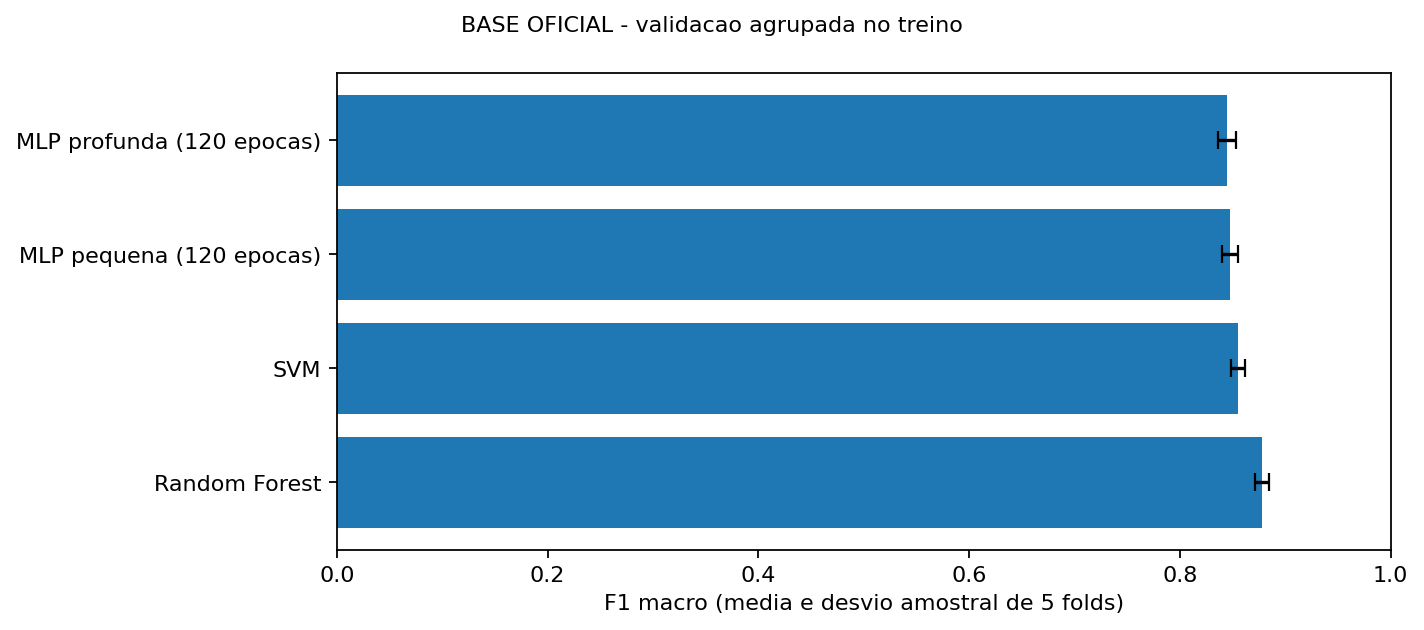

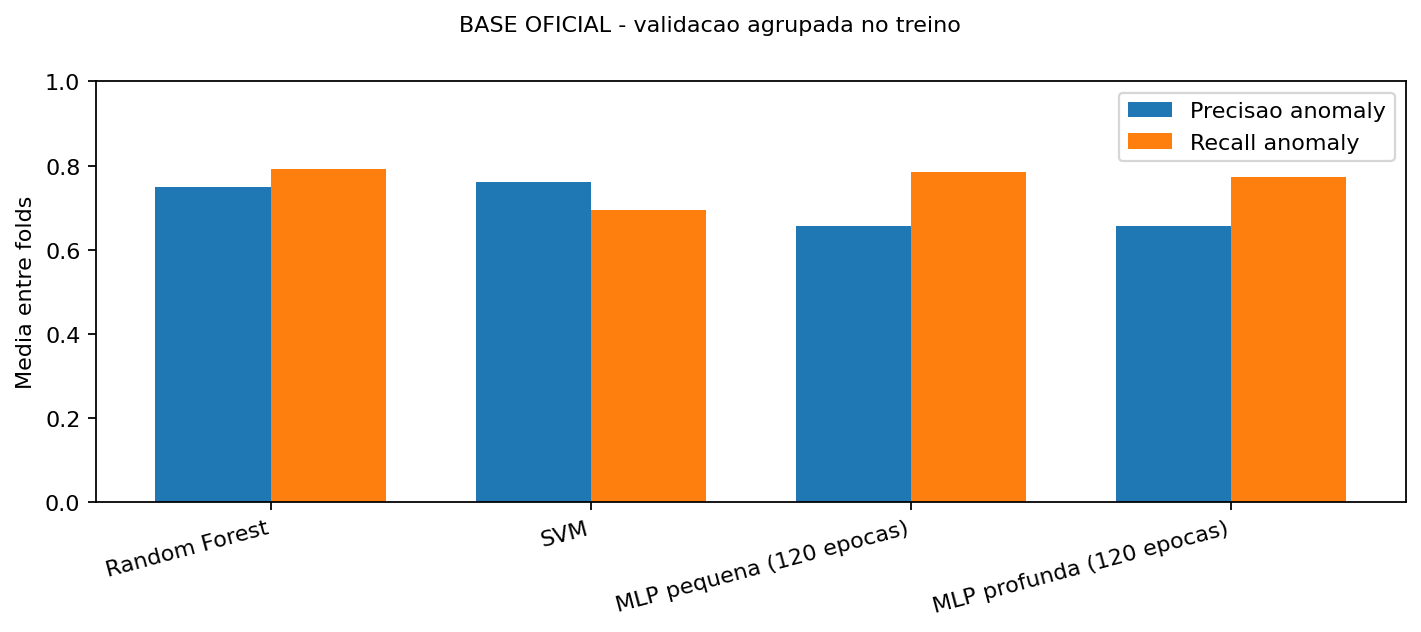

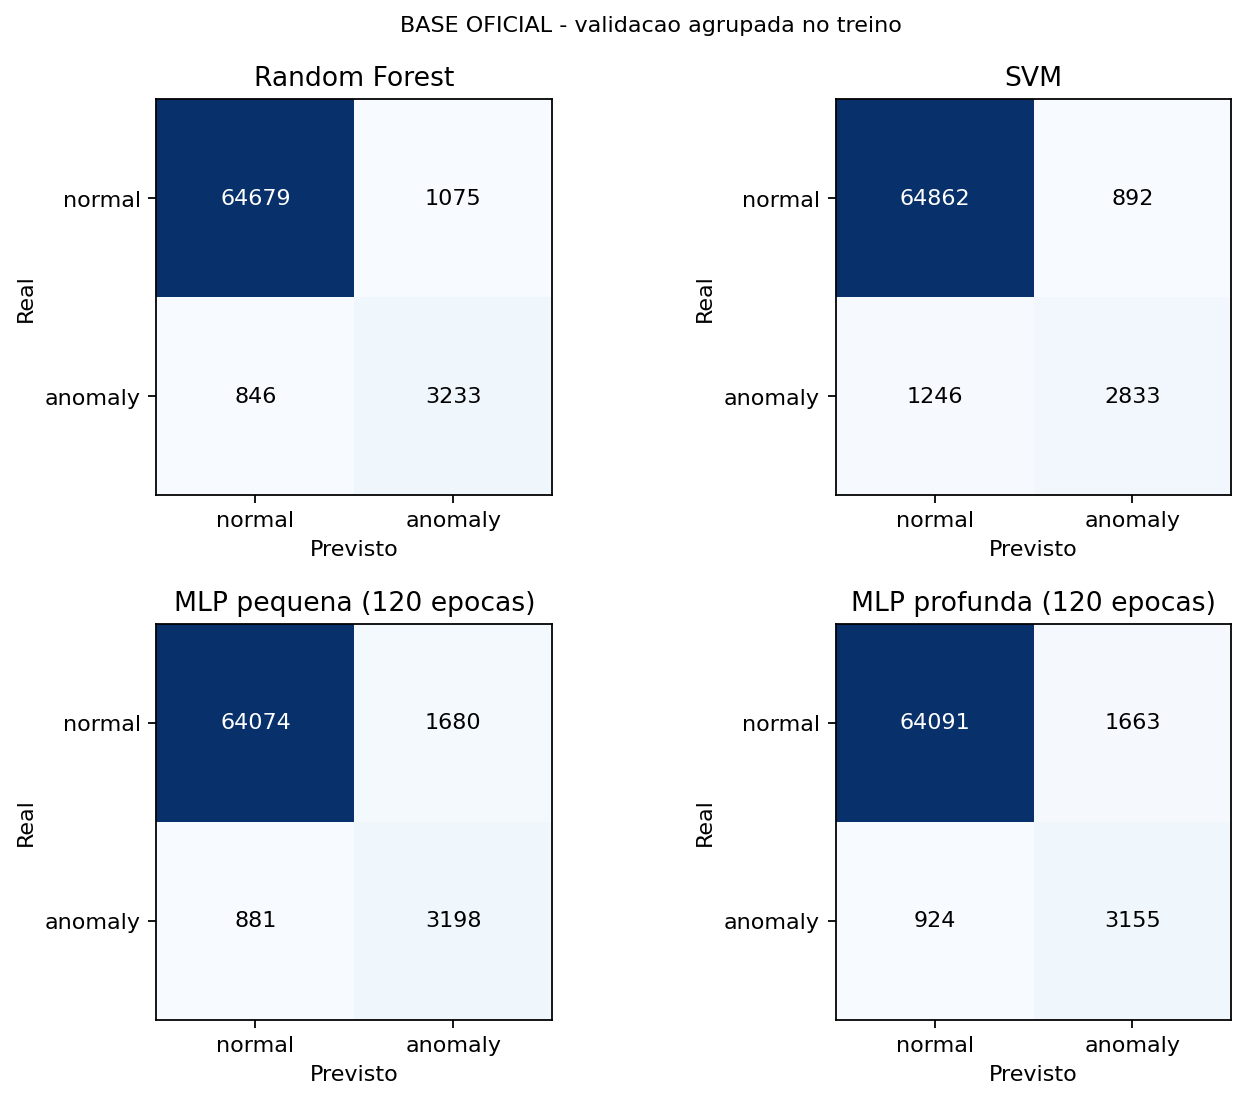

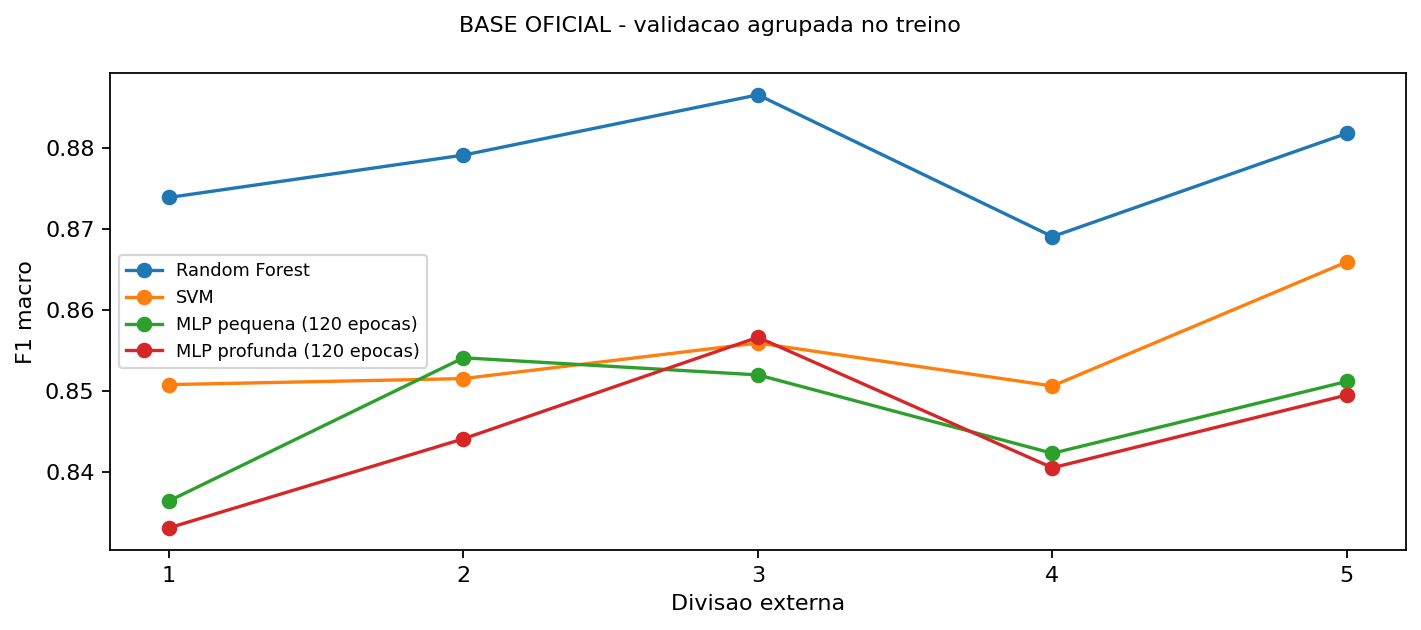

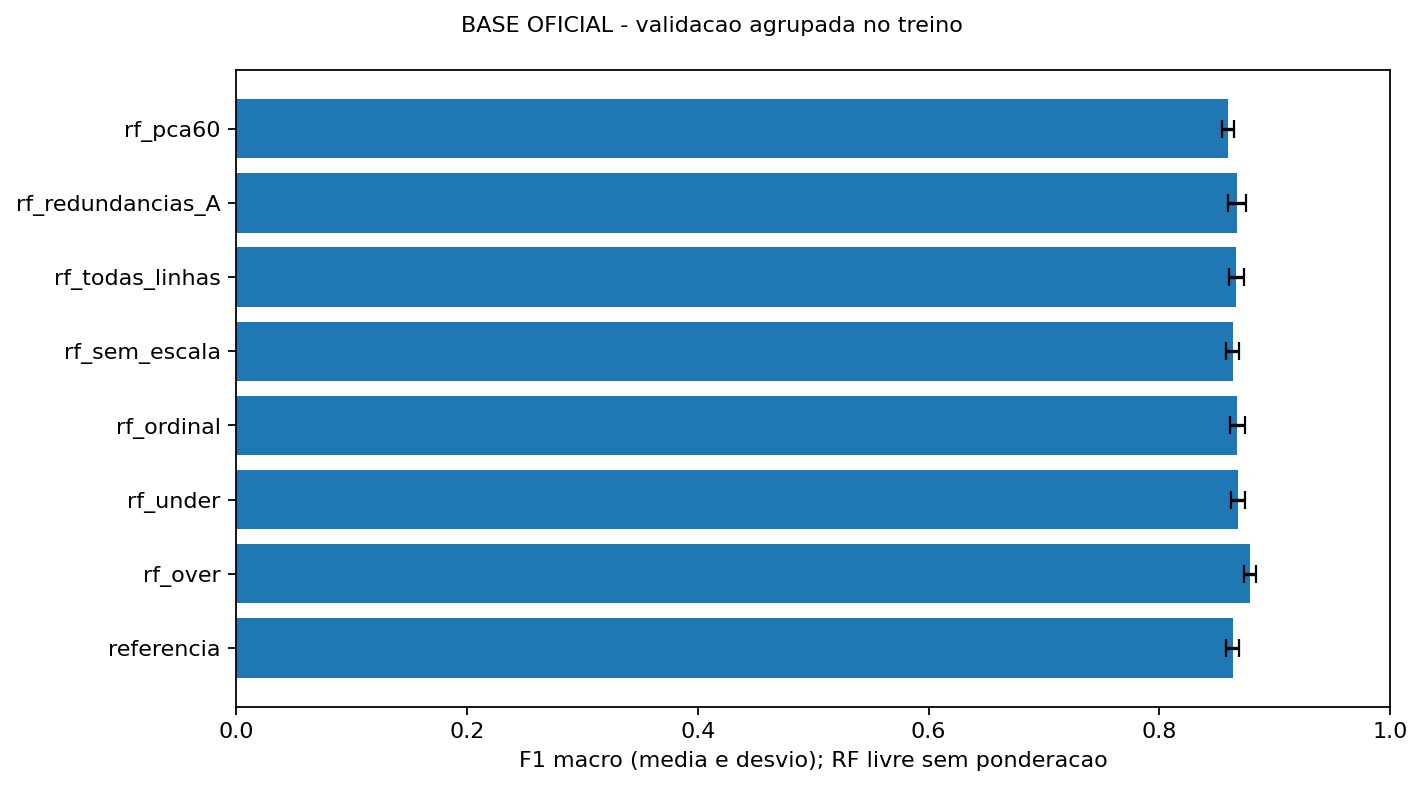

In [10]:
for nome in ("f1_algoritmos.png", "precisao_recall.png", "matrizes_confusao.png", "variacao_divisoes.png", "efeito_preprocessamento.png"):
    display(Image(filename=str(SAIDA / nome)))

In [11]:
resultado = json.loads((SAIDA / "resultados.json").read_text(encoding="utf-8"))
selecao = resultado["selecao"]
display(Markdown(f"**Comparação selecionada:** {selecao['comparacao_selecionada']}. "
                 f"**Configuração recomendada:** {selecao['configuracao_recomendada']}."))
display(Markdown(selecao["criterio"] + " " + selecao["limite"]))
selecionada = next((c for c in resultado["configuracoes"] if c["nome"] == selecao["configuracao_recomendada"]), None)
print(json.dumps(selecionada, ensure_ascii=False, indent=2))

**Comparação selecionada:** preparo:rf_over. **Configuração recomendada:** rf_over.

F1 macro externo medio; recall anomaly; nome em empate. Configuracao por medias internas. Escolha informada pela comparacao externa; desempenho do vencedor nao e estimativa final independente. Folds internos sobrepostos nao sao repeticoes independentes. Quinta historica reutilizada.

{
  "nome": "rf_over",
  "modelo": "random_forest",
  "parametros": {
    "n_estimators": 100,
    "max_depth": null,
    "class_weight": null,
    "min_samples_leaf": 2,
    "max_features": "sqrt",
    "criterion": "gini"
  },
  "linhas": "sem_duplicatas",
  "numericos": "mediana",
  "nominais": "ausencia",
  "codificacao": "onehot",
  "escala": "zscore",
  "balanceamento": "over_0_5",
  "representacao": "C",
  "reducao": "nenhuma"
}


## Justificativa e conclusões da Etapa 3

A recomendação usa F1-macro médio; precisão/recall de anomalias, falsos positivos/negativos,
gap treino-validação, desvio e tempo nas tabelas permitem avaliar o custo da escolha.
A comparação externa participa da seleção final: o desempenho do vencedor pode ser otimista.
`selecao_global_aninhada` mede separadamente o procedimento que escolhe candidatos somente
pelos folds internos; tampouco elimina o conhecimento histórico da base.

O diagnóstico não altera épocas ou hiperparâmetros após observar os resultados externos.
O treino integral do pipeline para submissão, inferência no teste, explicabilidade e relatório
acadêmico final pertencem a etapas futuras. Permanecem pendentes a proveniência dos três
sinais excluídos e o significado de `su_attempted=2`. Os resultados são específicos desta base,
semente e orçamento; não demonstram desempenho sobre tráfego contemporâneo.

**Declaração de uso de IA generativa.** O Codex auxiliou na organização do código,
na construção do notebook, na execução dos experimentos, na conferência dos registros
e na redação técnica. Os dados, parâmetros, métricas e limitações apresentados são
verificáveis pelas células e pelos resultados registrados; a equipe é responsável pela
revisão e interpretação acadêmica do trabalho.